In [ ]:
import pandas as pd
import numpy as np

ratings_url = "https://files.grouplens.org/datasets/movielens/ml-100k/u.data"

columns = ["user_id", "movie_id", "rating", "timestamp"]

ratings = pd.read_csv( ratings_url, sep="\t", names=columns )

print(ratings.head())
print("\nShape:", ratings.shape)

print("\nMissing values:")
print(ratings.isnull().sum())

   user_id  movie_id  rating  timestamp
0      196       242       3  881250949
1      186       302       3  891717742
2       22       377       1  878887116
3      244        51       2  880606923
4      166       346       1  886397596

Shape: (100000, 4)

Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


In [ ]:
print("Number of users:", ratings["user_id"].nunique())
print("Number of movies:", ratings["movie_id"].nunique())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nAverage rating:", ratings["rating"].mean())

print("\nRatings per user:")
print(ratings.groupby("user_id")["rating"].count().describe())

print("\nRatings per movie:")
print(ratings.groupby("movie_id")["rating"].count().describe())

Number of users: 943
Number of movies: 1682

Rating distribution:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

Average rating: 3.52986

Ratings per user:
count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
Name: rating, dtype: float64

Ratings per movie:
count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
Name: rating, dtype: float64


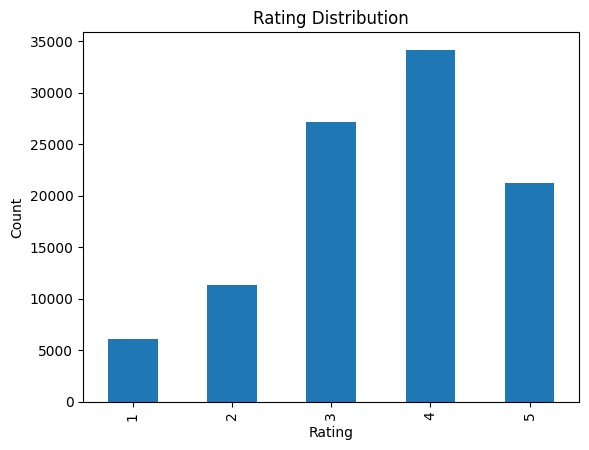

In [ ]:
import matplotlib.pyplot as plt

ratings["rating"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Rating Distribution")

plt.show()

In [ ]:
total_possible_ratings = ratings["user_id"].nunique() * ratings["movie_id"].nunique()

actual_ratings = len(ratings)

sparsity = 1 - (actual_ratings / total_possible_ratings)

print("Possible user-movie interactions:", total_possible_ratings)
print("Actual ratings:", actual_ratings)
print("Sparsity:", sparsity)
print("Sparsity percentage:", sparsity * 100)

Possible user-movie interactions: 1586126
Actual ratings: 100000
Sparsity: 0.9369533063577546
Sparsity percentage: 93.69533063577546


# METHOD 1

• rating_count = ... → This tells Pandas: "Create a brand new column in the final result and name it rating_count."
• ("rating", ...) → This tells Pandas: "Go look at the existing column in your original data named rating."
• ..., "count") → This tells Pandas: "Run the built-in string function "count" on that column to find the total number of entries."

In [ ]:
movie_stats = ratings.groupby("movie_id").agg(rating_count=("rating", "count"), average_rating=("rating", "mean") ).reset_index()

print(movie_stats.head())

   movie_id  rating_count  average_rating
0         1           452        3.878319
1         2           131        3.206107
2         3            90        3.033333
3         4           209        3.550239
4         5            86        3.302326


#popularity baseline

In [ ]:
popular_movies = movie_stats[movie_stats["rating_count"] >= 50]

popular_movies = popular_movies.sort_values(
    by=["average_rating", "rating_count"],
    ascending=[False, False]
)

print(popular_movies.head(10))

     movie_id  rating_count  average_rating
407       408           112        4.491071
317       318           298        4.466443
168       169           118        4.466102
482       483           243        4.456790
113       114            67        4.447761
63         64           283        4.445230
602       603           209        4.387560
11         12           267        4.385768
49         50           583        4.358491
177       178           125        4.344000


In [ ]:
movies_url = "https://files.grouplens.org/datasets/movielens/ml-100k/u.item"

movie_columns = [
    "movie_id", "title", "release_date", "video_release_date", "imdb_url",
    "unknown", "Action", "Adventure", "Animation", "Children", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"
]

movies = pd.read_csv(movies_url, sep="|", names=movie_columns, encoding="latin-1")

print(movies[['movie_id', 'title']].head())

   movie_id              title
0         1   Toy Story (1995)
1         2   GoldenEye (1995)
2         3  Four Rooms (1995)
3         4  Get Shorty (1995)
4         5     Copycat (1995)


In [ ]:
popular_movies_with_titles = popular_movies.merge(movies[['movie_id', 'title']], on='movie_id', how='left')

print(popular_movies_with_titles[['movie_id', 'title', 'rating_count', 'average_rating']].head(5))

   movie_id                                              title  rating_count  \
0       408                              Close Shave, A (1995)           112   
1       318                            Schindler's List (1993)           298   
2       169                         Wrong Trousers, The (1993)           118   
3       483                                  Casablanca (1942)           243   
4       114  Wallace & Gromit: The Best of Aardman Animatio...            67   

   average_rating  
0        4.491071  
1        4.466443  
2        4.466102  
3        4.456790  
4        4.447761  


personalized recommendations using user-based collaborative filtering

In [ ]:
user_item_matrix = ratings.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

print(user_item_matrix.shape)
print(user_item_matrix.head())

(943, 1682)
movie_id  1     2     3     4     5     6     7     8     9     10    ...  \
user_id                                                               ...   
1          5.0   3.0   4.0   3.0   3.0   5.0   4.0   1.0   5.0   3.0  ...   
2          4.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   2.0  ...   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   
5          4.0   3.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...   

movie_id  1673  1674  1675  1676  1677  1678  1679  1680  1681  1682  
user_id                                                               
1          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
2          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
5          NaN   NaN  

In [ ]:
user_item_filled = user_item_matrix.fillna(0)
print(user_item_filled.head())

movie_id  1     2     3     4     5     6     7     8     9     10    ...  \
user_id                                                               ...   
1          5.0   3.0   4.0   3.0   3.0   5.0   4.0   1.0   5.0   3.0  ...   
2          4.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   2.0  ...   
3          0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   
4          0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   
5          4.0   3.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   

movie_id  1673  1674  1675  1676  1677  1678  1679  1680  1681  1682  
user_id                                                               
1          0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
2          0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
3          0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
4          0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
5          0.0   0.0   0.0   0.0  

user similarity: comparing every user with every other user.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(user_item_filled)

print(user_similarity.shape)
print(user_similarity)

(943, 943)
[[1.         0.16693098 0.04745954 ... 0.14861694 0.17950788 0.39817474]
 [0.16693098 1.         0.11059132 ... 0.16148478 0.17226781 0.10579788]
 [0.04745954 0.11059132 1.         ... 0.10124256 0.13341615 0.02655587]
 ...
 [0.14861694 0.16148478 0.10124256 ... 1.         0.1016418  0.09511958]
 [0.17950788 0.17226781 0.13341615 ... 0.1016418  1.         0.18246466]
 [0.39817474 0.10579788 0.02655587 ... 0.09511958 0.18246466 1.        ]]


In [ ]:
user_similarity_df = pd.DataFrame(user_similarity, index = user_item_matrix.index, columns=user_item_matrix.index)
print(user_similarity_df.head())

user_id       1         2         3         4         5         6         7    \
user_id                                                                         
1        1.000000  0.166931  0.047460  0.064358  0.378475  0.430239  0.440367   
2        0.166931  1.000000  0.110591  0.178121  0.072979  0.245843  0.107328   
3        0.047460  0.110591  1.000000  0.344151  0.021245  0.072415  0.066137   
4        0.064358  0.178121  0.344151  1.000000  0.031804  0.068044  0.091230   
5        0.378475  0.072979  0.021245  0.031804  1.000000  0.237286  0.373600   

user_id       8         9         10   ...       934       935       936  \
user_id                                ...                                 
1        0.319072  0.078138  0.376544  ...  0.369527  0.119482  0.274876   
2        0.103344  0.161048  0.159862  ...  0.156986  0.307942  0.358789   
3        0.083060  0.061040  0.065151  ...  0.031875  0.042753  0.163829   
4        0.188060  0.101284  0.060859  ...  0.052107

In [ ]:
target_user = 1

top_similar_users = ( user_similarity_df[target_user] .drop(target_user) .sort_values(ascending=False) .head(5) )

print(top_similar_users)

user_id
916    0.569066
864    0.547548
268    0.542077
92     0.540534
435    0.538665
Name: 1, dtype: float64


In [ ]:
target_user_ratings = user_item_matrix.loc[target_user]

rated_movies = target_user_ratings[target_user_ratings.notna()].index

print("Movies already rated by User 1:", len(rated_movies))

Movies already rated by User 1: 272


In [ ]:
similar_users_ratings = user_item_matrix.loc[top_similar_users.index]

print(similar_users_ratings.head())

movie_id  1     2     3     4     5     6     7     8     9     10    ...  \
user_id                                                               ...   
916        4.0   3.0   3.0   4.0   3.0   NaN   4.0   NaN   5.0   NaN  ...   
864        5.0   4.0   NaN   4.0   4.0   NaN   5.0   5.0   5.0   NaN  ...   
268        3.0   2.0   1.0   4.0   NaN   NaN   4.0   NaN   NaN   4.0  ...   
92         4.0   3.0   NaN   4.0   4.0   NaN   4.0   5.0   4.0   NaN  ...   
435        5.0   4.0   3.0   4.0   2.0   NaN   4.0   3.0   4.0   5.0  ...   

movie_id  1673  1674  1675  1676  1677  1678  1679  1680  1681  1682  
user_id                                                               
916        NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   3.0  
864        NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
268        NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
92         NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
435        NaN   NaN   NaN   NaN  

In [ ]:
# Average rating from the top similar users
movie_scores = similar_users_ratings.mean(axis=0)

# Remove movies already rated by User 1
movie_scores = movie_scores.drop(rated_movies, errors="ignore")

# Sort highest score first
recommendations = movie_scores.sort_values(ascending=False)

print(recommendations.head(10))

movie_id
302     5.0
313     5.0
343     5.0
331     5.0
430     5.0
736     5.0
963     5.0
919     5.0
855     5.0
1009    5.0
dtype: float64


similarity-weighted ratings. weighted score = rating × similarity

In [ ]:
top_similar_users.index

Index([916, 864, 268, 92, 435], dtype='int64', name='user_id')

In [ ]:
user_item_matrix.loc[916]

,916
movie_id,
1,4.0
2,3.0
3,3.0
4,4.0
5,3.0
...,...
1678,NaN
1679,NaN
1680,NaN


In [ ]:
similar_users_ratings

movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
916,4.0,3.0,3.0,4.0,3.0,NaN,4.0,NaN,5.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0
864,5.0,4.0,NaN,4.0,4.0,NaN,5.0,5.0,5.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
268,3.0,2.0,1.0,4.0,NaN,NaN,4.0,NaN,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92,4.0,3.0,NaN,4.0,4.0,NaN,4.0,5.0,4.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
435,5.0,4.0,3.0,4.0,2.0,NaN,4.0,3.0,4.0,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
top_similar_users

,1
user_id,
916,0.569066
864,0.547548
268,0.542077
92,0.540534
435,0.538665


In [ ]:
# Ratings from top similar users
similar_users_ratings = user_item_matrix.loc[top_similar_users.index]

# Multiply each user's ratings by their similarity score
weighted_ratings = similar_users_ratings.mul(top_similar_users,axis=0)

# Sum weighted ratings for each movie
weighted_sum = weighted_ratings.sum(axis=0)

# Sum similarities only for users who actually rated each movie
similarity_sum = (
    similar_users_ratings.notna()
    .mul(top_similar_users, axis=0)
    .sum(axis=0)
)

# Final weighted recommendation score
weighted_scores = weighted_sum / similarity_sum

# Remove movies User 1 already rated
weighted_scores = weighted_scores.drop(
    rated_movies,
    errors="ignore"
)

# Sort best recommendations
weighted_recommendations = weighted_scores.sort_values(
    ascending=False
)

print(weighted_recommendations.head(10))

movie_id
919     5.0
302     5.0
1009    5.0
855     5.0
430     5.0
736     5.0
343     5.0
963     5.0
331     5.0
313     5.0
dtype: float64


# Method 2 using Light GCN MODEL

In [ ]:
positive_ratings = ratings[ratings["rating"] >= 4].copy()

print(positive_ratings.head())
print("Positive interactions:", len(positive_ratings))

    user_id  movie_id  rating  timestamp
5       298       474       4  884182806
7       253       465       5  891628467
11      286      1014       5  879781125
12      200       222       5  876042340
16      122       387       5  879270459
Positive interactions: 55375


In [ ]:
user_ids = positive_ratings["user_id"].unique()
movie_ids = positive_ratings["movie_id"].unique()

user_to_idx = { user_id: idx for idx, user_id in enumerate(user_ids) }

movie_to_idx = { movie_id: idx for idx, movie_id in enumerate(movie_ids) }

In [ ]:
positive_ratings["user_idx"] = positive_ratings["user_id"].map(user_to_idx)

positive_ratings["movie_idx"] = positive_ratings["movie_id"].map(movie_to_idx)

print( positive_ratings[ ["user_id", "user_idx", "movie_id", "movie_idx", "rating"] ].head() )

    user_id  user_idx  movie_id  movie_idx  rating
5       298         0       474          0       4
7       253         1       465          1       5
11      286         2      1014          2       5
12      200         3       222          3       5
16      122         4       387          4       5


In [ ]:
print("Number of users:", len(user_to_idx))
print("Number of movies:", len(movie_to_idx))

Number of users: 942
Number of movies: 1447


In [ ]:
train_rows = []
test_rows = []

#groups together all positive interactions for each user.
for user_idx, group in positive_ratings.groupby("user_idx"):
    group = group.sample(frac=1, random_state=42)

    if len(group) > 1:
        test_rows.append(group.iloc[0])
        train_rows.append(group.iloc[1:])
    else:
        train_rows.append(group)

train_data = pd.concat(train_rows).reset_index(drop=True)
test_data = pd.DataFrame(test_rows).reset_index(drop=True)

print("Train interactions:", len(train_data))
print("Test interactions:", len(test_data))
print("Users in test:", test_data["user_idx"].nunique())

Train interactions: 54433
Test interactions: 942
Users in test: 942


In [ ]:
num_users = len(user_to_idx)
num_movies = len(movie_to_idx)

print("Users:", num_users)
print("Movies:", num_movies)

Users: 942
Movies: 1447


create edge lists

In [ ]:
user_nodes = train_data["user_idx"].values
movie_nodes = train_data["movie_idx"].values

print(len(user_nodes))
print(len(movie_nodes))

54433
54433


In [ ]:
movie_graph_nodes = movie_nodes + num_users

Now create edges:

In [ ]:
import torch

edge_index = torch.tensor( [user_nodes, movie_graph_nodes], dtype=torch.long )

print(edge_index.shape)
print(edge_index[:, :5])

torch.Size([2, 54433])
tensor([[   0,    0,    0,    0,    0],
        [1351, 1218, 1160,  942, 1108]])


/tmp/ipykernel_5684/1449997020.py:3: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  edge_index = torch.tensor(


So we'll make it bidirectional:

In [ ]:
reverse_edge_index = torch.stack([edge_index[1],edge_index[0]])

print("reverse_edge_index:", reverse_edge_index.shape)

edge_index = torch.cat([edge_index, reverse_edge_index], dim=1 )


print("Final edge shape:", edge_index.shape)

reverse_edge_index: torch.Size([2, 54433])
Final edge shape: torch.Size([2, 108866])


In [ ]:
import torch
import torch.nn as nn

class LightGCN(nn.Module):
    def __init__(self, num_users, num_movies, embedding_dim=64, num_layers=3):
        super().__init__()

        self.num_users = num_users
        self.num_movies = num_movies
        self.num_nodes = num_users + num_movies
        self.embedding_dim = embedding_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(self.num_nodes,embedding_dim)

        nn.init.xavier_uniform_(self.embedding.weight)

    def forward(self, edge_index):

      embeddings = self.embedding.weight #shape [num_users + num_movies, 64]

      all_embeddings = [embeddings]

      source = edge_index[0]
      destination = edge_index[1]

      # Number of connections for every node
      degree = torch.bincount(
          source,
          minlength=self.num_nodes
      ).float()

      # 1 / sqrt(degree)
      degree_inv_sqrt = degree.pow(-0.5)

      # Handle nodes with degree 0
      degree_inv_sqrt[torch.isinf(degree_inv_sqrt) ] = 0


      # Weight for every edge
      norm = (
          degree_inv_sqrt[source]
          *
          degree_inv_sqrt[destination]
      )

      for _ in range(self.num_layers):

          #empty new embedding matrix
          new_embeddings = torch.zeros_like(embeddings)

          messages = ( embeddings[source] * norm.unsqueeze(1) )

          new_embeddings.index_add_(0,destination,messages)

          embeddings = new_embeddings

          all_embeddings.append(embeddings)

      final_embeddings = torch.stack(
          all_embeddings,
          dim=0
      ).mean(dim=0)

      return final_embeddings

In [ ]:
def bpr_loss(user_emb, pos_emb, neg_emb):
    pos_scores = (user_emb * pos_emb).sum(dim=1)
    neg_scores = (user_emb * neg_emb).sum(dim=1)

    loss = -torch.log(
        torch.sigmoid(pos_scores - neg_scores) + 1e-8
    ).mean()

    return loss

In [ ]:
model = LightGCN(
    num_users=num_users,
    num_movies=num_movies,
    embedding_dim=64,
    num_layers=3
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
train_users = torch.tensor(
    train_data["user_idx"].values,
    dtype=torch.long
)

train_pos_movies = torch.tensor(
    train_data["movie_idx"].values,
    dtype=torch.long
)

In [ ]:
user_positive_movies = ( train_data.groupby("user_idx")["movie_idx"] .apply(set) .to_dict() )

negative_movies_list = []

for user in train_users.tolist():

    while True:
        neg_movie = torch.randint(
            0,
            num_movies,
            (1,)
        ).item()

        if neg_movie not in user_positive_movies[user]:
            negative_movies_list.append(neg_movie)
            break

negative_movies = torch.tensor(
    negative_movies_list,
    dtype=torch.long
)

In [ ]:
num_epochs = 20

for epoch in range(num_epochs):

    model.train()
    optimizer.zero_grad()

    final_embeddings = model(edge_index)

    user_embeddings = final_embeddings[:num_users]
    movie_embeddings = final_embeddings[num_users:]

    # movies a user hasn't interacted with
    # negative_movies = torch.randint( 0, num_movies, size=train_pos_movies.shape )

    u_emb = user_embeddings[train_users]
    pos_emb = movie_embeddings[train_pos_movies]
    neg_emb = movie_embeddings[negative_movies]

    loss = bpr_loss(
        u_emb,
        pos_emb,
        neg_emb
    )

    loss.backward()
    optimizer.step()

    print(
        f"Epoch {epoch+1}/{num_epochs} - Loss: {loss.item():.4f}"
    )

Epoch 1/20 - Loss: 0.6931
Epoch 2/20 - Loss: 0.6930
Epoch 3/20 - Loss: 0.6930
Epoch 4/20 - Loss: 0.6929
Epoch 5/20 - Loss: 0.6927
Epoch 6/20 - Loss: 0.6926
Epoch 7/20 - Loss: 0.6924
Epoch 8/20 - Loss: 0.6921
Epoch 9/20 - Loss: 0.6918
Epoch 10/20 - Loss: 0.6915
Epoch 11/20 - Loss: 0.6911
Epoch 12/20 - Loss: 0.6907
Epoch 13/20 - Loss: 0.6902
Epoch 14/20 - Loss: 0.6896
Epoch 15/20 - Loss: 0.6890
Epoch 16/20 - Loss: 0.6884
Epoch 17/20 - Loss: 0.6877
Epoch 18/20 - Loss: 0.6869
Epoch 19/20 - Loss: 0.6861
Epoch 20/20 - Loss: 0.6852


# EVALUATION

In [ ]:
model.eval()

with torch.no_grad():
    final_embeddings = model(edge_index)

user_embeddings = final_embeddings[:num_users]
movie_embeddings = final_embeddings[num_users:]

In [ ]:
hits = 0
k = 10

for _, row in test_data.iterrows():

    user_idx = int(row["user_idx"])
    test_movie = int(row["movie_idx"])

    # Get this user's embedding
    user_emb = user_embeddings[user_idx]

    # Score every movie
    scores = torch.matmul(
        movie_embeddings,
        user_emb
    )

    # Remove movies already seen during training
    seen_movies = user_positive_movies[user_idx]

    scores[list(seen_movies)] = float("-inf")

    # Top K movies
    top_k_movies = torch.topk(
        scores,
        k=k
    ).indices.tolist()

    # Check whether held-out movie was recovered
    if test_movie in top_k_movies:
        hits += 1

hit_rate_at_10 = hits / len(test_data)

print("Hit Rate@10:", hit_rate_at_10)

Hit Rate@10: 0.11995753715498939


In [ ]:
import math

ndcg_scores = []
k = 10

for _, row in test_data.iterrows():

    user_idx = int(row["user_idx"])
    test_movie = int(row["movie_idx"])

    user_emb = user_embeddings[user_idx]

    scores = torch.matmul(
        movie_embeddings,
        user_emb
    )

    seen_movies = user_positive_movies[user_idx]

    scores[list(seen_movies)] = float("-inf")

    top_k_movies = torch.topk(
        scores,
        k=k
    ).indices.tolist()

    if test_movie in top_k_movies:

        rank = top_k_movies.index(test_movie) + 1

        ndcg = 1 / math.log2(rank + 1)

    else:
        ndcg = 0

    ndcg_scores.append(ndcg)

ndcg_at_10 = sum(ndcg_scores) / len(ndcg_scores)

print("NDCG@10:", ndcg_at_10)

NDCG@10: 0.06201642563246528
